# 그룹 교차검증 — 처음 보는 생산 조건에서의 성능
- **그룹:** 같은 생산 조건(강종 `TypeOfSteel_A300` · 두께 `Steel_Plate_Thickness` · 폭 `Length_of_Conveyer`) 묶음
- **방법:** `StratifiedGroupKFold(5)` — 같은 그룹은 학습/검증 중 한쪽에만 들어감 → 검증 결함은 모두 "처음 보는 조건"
- **비교:** 기존 `StratifiedKFold(5)`(팀 공통 CV)와 같은 모델·파라미터로 비교. 그룹 CV는 분할 난수 3개(42·43·44)로 반복해 15 fold
- Train만 사용 (Test 미사용). `RERUN = False`면 저장된 결과(`results/group_cv/`)를 불러옴

In [1]:
import sys, warnings, pickle, json, time
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

from config import RANDOM_STATE, CV
from load_data import load_data
from Taegyeom_model_utils import (CLASS_ORDER, PLATE_KEYS, make_pipeline, make_sampling_pipeline, build_preprocessor, discrete_indices,
                                  over_strategy, LabelEncodedClassifier, BalancedWeightClassifier, add_features, PlateContextEncoder)
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.metrics import f1_score, accuracy_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier, VotingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline as ImbPipeline
from joblib import Parallel, delayed

OUT = ROOT / "results" / "group_cv"; OUT.mkdir(parents=True, exist_ok=True)
RERUN = False                                             # True: 다시 계산
CACHE = OUT / "Taegyeom_group_cv_cache.pkl"
cache = pickle.load(open(CACHE, "rb")) if (CACHE.exists() and not RERUN) else {}
def cached(key, fn):
    if key not in cache:
        cache[key] = fn(); pickle.dump(cache, open(CACHE, "wb"))
    return cache[key]

for f in ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR", "Noto Sans CJK TC"]:
    if any(f == x.name for x in mpl.font_manager.fontManager.ttflist):
        mpl.rcParams["font.family"] = f; break
mpl.rcParams.update({"axes.unicode_minus": False, "figure.dpi": 100})
pd.set_option("display.width", 220)

## 1. 생산 조건 그룹 확인

In [2]:
X_train, _, y_train, _ = load_data()
RS = RANDOM_STATE
XF = add_features(X_train)                                            # 행 단위 파생변수 포함 34열
groups = X_train[PLATE_KEYS].astype(str).agg("_".join, axis=1)        # 생산 조건 = 폭_두께_강종

size = groups.value_counts()
print(f"Train {len(groups)}건, 생산 조건 {len(size)}개 | 1건짜리 조건 {(size == 1).sum()}개 | 최대 {size.max()}건")
print("조건당 결함 유형 수:", pd.crosstab(groups, y_train).gt(0).sum(axis=1).value_counts().sort_index().to_dict())

Train 1552건, 생산 조건 218개 | 1건짜리 조건 61개 | 최대 108건
조건당 결함 유형 수: {1: 117, 2: 68, 3: 23, 4: 7, 5: 3}


In [3]:
# 분할 만들기: 기존 5-fold(팀 공통) vs 그룹 5-fold × 난수 3개
SPLITS = {"기존 5-fold": [list(CV.split(XF, y_train))]}
SPLITS["그룹 5-fold ×3"] = [list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RS + r).split(XF, y_train, groups)) for r in range(3)]

# 그룹 분할 검증: 학습·검증에 같은 조건이 겹치지 않는지, 검증 fold 클래스 건수
g = groups.values
for rep in SPLITS["그룹 5-fold ×3"]:
    assert all(not set(g[tr]) & set(g[va]) for tr, va in rep)
print("그룹 분할: 모든 fold에서 학습/검증 생산 조건 겹침 없음")
cnt = pd.DataFrame([y_train.iloc[va].value_counts().reindex(CLASS_ORDER).fillna(0).astype(int) for va in [v for _, v in SPLITS["그룹 5-fold ×3"][0]]],
                   index=[f"fold{i + 1}" for i in range(5)])
display(cnt)   # 그룹 단위로 나누면 fold마다 클래스 건수가 고르지 않음 (특히 Stains·Dirtiness)
# 기존 5-fold에서 검증 결함 중 학습에 없던 조건 비율
print(f"기존 5-fold 검증 결함 중 처음 보는 조건 비율: {np.mean(np.concatenate([~np.isin(g[va], g[tr]) for tr, va in SPLITS['기존 5-fold'][0]])):.1%}")

그룹 분할: 모든 fold에서 학습/검증 생산 조건 겹침 없음


target,Other_Faults,Bumps,K_Scratch,Z_Scratch,Pastry,Stains,Dirtiness
fold1,108,64,80,13,26,9,8
fold2,107,64,55,53,25,1,8
fold3,108,65,56,27,25,17,8
fold4,108,64,56,46,25,1,13
fold5,107,64,66,13,25,30,7


기존 5-fold 검증 결함 중 처음 보는 조건 비율: 5.5%


## 2. 비교 모델

In [4]:
class PlateContextNoCount(TransformerMixin, BaseEstimator):   # plate_defect_count 없이 thickness_per_conveyer만 생성
    def fit(self, X, y=None): return self
    def transform(self, X):
        out = X.copy(); out["thickness_per_conveyer"] = X["Steel_Plate_Thickness"] / X["Length_of_Conveyer"]; return out

FEAT = list(X_train.columns)
F36 = list(XF.columns) + ["plate_defect_count", "thickness_per_conveyer"]
F35 = list(XF.columns) + ["thickness_per_conveyer"]
best = lambda r: r.loc[r["rank_test_score"].idxmin(), "params"]

# 튜닝 LightGBM (04번 결과)
cfg = json.load(open(ROOT / "results/tuning/Taegyeom_tuning_best_config.json", encoding="utf-8"))
LGBM_P = {k: v for k, v in cfg["params"].items() if k != "sampler"}
smote26 = lambda: SMOTENC(categorical_features=discrete_indices(FEAT), sampling_strategy=over_strategy(1), k_neighbors=5, random_state=RS)

# 최종 Soft Voting (06번 결과). 포함 = 36개 / 제외 = 35개
ens = pickle.load(open(ROOT / "results/ensemble/Taegyeom_ensemble_cache.pkl", "rb"))
P36 = {n: best(ens[("search", n)]) for n in ["ExtraTrees", "Random Forest", "GBM"]}
abl = ROOT / "results/ablation/Taegyeom_ablation_plate_count_cache.pkl"      # 11번 재튜닝 결과가 있으면 사용
abl_c = pickle.load(open(abl, "rb")) if abl.exists() else {}
use_abl = all(("search", n) in abl_c for n in P36)
P35 = {n: best(abl_c[("search", n)]) for n in P36} if use_abl else P36
print("제외 설정 파라미터:", "11번 재튜닝 결과" if use_abl else "최종 모델 파라미터 그대로 (11번 실행 후 RERUN=True로 다시 돌리면 재튜닝 값 사용)")

def soft_voting(enc, feats, params):   # 샘플러 없음(저장된 파라미터에 sampler가 있으면 그 값 적용)
    p = lambda m: ImbPipeline([("plate", enc()), ("prep", build_preprocessor(feats)), ("sampler", "passthrough"), ("model", m)])
    members = [("extratrees", p(ExtraTreesClassifier(random_state=RS, n_jobs=1)).set_params(**params["ExtraTrees"])),
               ("rf", p(RandomForestClassifier(random_state=RS, n_jobs=1)).set_params(**params["Random Forest"])),
               ("gbm", p(BalancedWeightClassifier(GradientBoostingClassifier(random_state=RS), alpha=1)).set_params(**params["GBM"]))]
    return VotingClassifier(members, voting="soft")

MODELS = {   # 이름: (생성 함수, 입력 데이터)
    "XGBoost (Baseline)": (lambda: make_pipeline(LabelEncodedClassifier(XGBClassifier(random_state=RS, n_jobs=1)), FEAT), X_train),
    "LightGBM 튜닝 (26개)": (lambda: make_sampling_pipeline(LGBMClassifier(random_state=RS, n_jobs=1, verbose=-1, subsample_freq=1, **LGBM_P), FEAT, smote26()), X_train),
    "Soft Voting 최종 (36개, count 포함)": (lambda: soft_voting(PlateContextEncoder, F36, P36), XF),
    "Soft Voting (35개, count 제외)": (lambda: soft_voting(PlateContextNoCount, F35, P35), XF),
}

제외 설정 파라미터: 11번 재튜닝 결과


## 3. 기존 CV vs 그룹 CV

In [5]:
def fold_pred(name, cv, r, k):   # fold 하나 학습 → 검증 예측
    make, X = MODELS[name]; tr, va = SPLITS[cv][r][k]
    m = make(); m.fit(X.iloc[tr], y_train.iloc[tr])
    return name, cv, r, k, m.predict(X.iloc[va])

def run_all():
    jobs = [(n, cv, r, k) for n in MODELS for cv in SPLITS for r in range(len(SPLITS[cv])) for k in range(5)]
    return {(n, cv, r, k): p for n, cv, r, k, p in Parallel(n_jobs=-1)(delayed(fold_pred)(*j) for j in jobs)}
t0 = time.perf_counter(); PRED = cached("pred", run_all); print(f"소요 {time.perf_counter() - t0:.0f}초")

yv = y_train.values
def summarize(name, cv):
    fold_f1, oof_f1, oof_acc, oofs = [], [], [], []
    for r, rep in enumerate(SPLITS[cv]):
        oof = np.empty(len(yv), dtype=object)
        for k, (_, va) in enumerate(rep):
            p = PRED[(name, cv, r, k)]; oof[va] = p; fold_f1.append(f1_score(yv[va], p, average="macro"))
        oof_f1.append(f1_score(yv, oof, average="macro")); oof_acc.append(accuracy_score(yv, oof)); oofs.append(oof)
    return np.array(fold_f1), np.mean(oof_f1), np.mean(oof_acc), oofs

S = {(n, cv): summarize(n, cv) for n in MODELS for cv in SPLITS}
rows = []
for n in MODELS:
    a, b = S[(n, "기존 5-fold")], S[(n, "그룹 5-fold ×3")]
    rows.append({"모델": n, "기존 5-fold Macro F1": a[0].mean(), "기존 std": a[0].std(),
                 "그룹 CV Macro F1 (fold 평균)": b[0].mean(), "그룹 std": b[0].std(),
                 "기존 OOF Macro F1": a[1], "그룹 OOF Macro F1": b[1], "하락 (OOF)": b[1] - a[1],
                 "기존 Accuracy": a[2], "그룹 Accuracy": b[2]})
res = pd.DataFrame(rows).set_index("모델")
res.to_csv(OUT / "Taegyeom_group_cv_summary.csv", encoding="utf-8-sig")
display(res.round(4))
# fold 평균: 그룹 fold는 소수 클래스가 1건뿐인 fold도 있어 흔들림이 큼 → OOF(Train 전체 예측을 모아 한 번에 계산)도 함께 봄

소요 33초


,기존 5-fold Macro F1,기존 std,그룹 CV Macro F1 (fold 평균),그룹 std,기존 OOF Macro F1,그룹 OOF Macro F1,하락 (OOF),기존 Accuracy,그룹 Accuracy
모델,,,,,,,,,
XGBoost (Baseline),0.8109,0.0308,0.7197,0.0424,0.8143,0.7588,-0.0555,0.7945,0.7296
LightGBM 튜닝 (26개),0.8309,0.0212,0.7365,0.0441,0.8325,0.7727,-0.0598,0.8086,0.7390
"Soft Voting 최종 (36개, count 포함)",0.8441,0.0188,0.7184,0.0467,0.8446,0.7650,-0.0796,0.8183,0.7328
"Soft Voting (35개, count 제외)",0.8368,0.0179,0.7566,0.0544,0.8372,0.7837,-0.0535,0.8112,0.7496


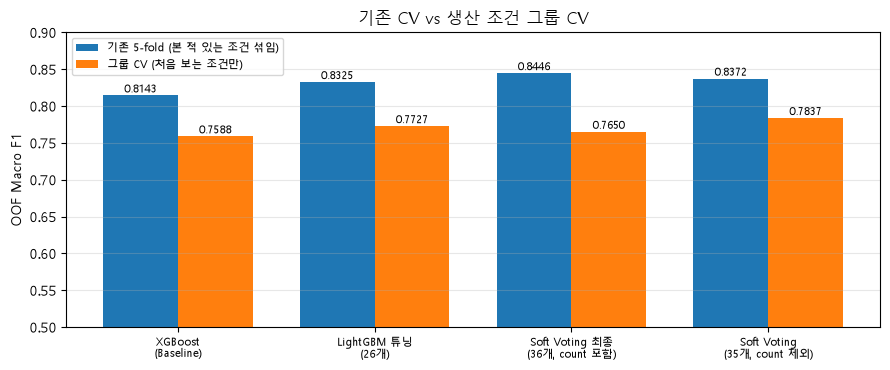

In [6]:
# 모델별 기존 vs 그룹 CV (OOF Macro F1)
fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(res)); w = 0.38
ax.bar(x - w / 2, res["기존 OOF Macro F1"], w, label="기존 5-fold (본 적 있는 조건 섞임)")
ax.bar(x + w / 2, res["그룹 OOF Macro F1"], w, label="그룹 CV (처음 보는 조건만)")
for i, (a, b) in enumerate(zip(res["기존 OOF Macro F1"], res["그룹 OOF Macro F1"])):
    ax.text(i - w / 2, a + 0.004, f"{a:.4f}", ha="center", fontsize=8); ax.text(i + w / 2, b + 0.004, f"{b:.4f}", ha="center", fontsize=8)
ax.set_xticks(x, [n.replace(" (", chr(10) + "(") for n in res.index], fontsize=8)
ax.set_ylim(0.5, 0.9); ax.set_ylabel("OOF Macro F1"); ax.legend(fontsize=8, loc="upper left"); ax.grid(alpha=0.3, axis="y")
ax.set_title("기존 CV vs 생산 조건 그룹 CV"); plt.tight_layout(); plt.show()

In [7]:
# 클래스별 F1: 처음 보는 조건에서 어떤 결함 유형이 특히 어려워지는가 (최종 모델, OOF)
FINAL = "Soft Voting 최종 (36개, count 포함)"
pc = pd.DataFrame({cv: np.mean([f1_score(yv, o, labels=CLASS_ORDER, average=None) for o in S[(FINAL, cv)][3]], axis=0)
                   for cv in SPLITS}, index=CLASS_ORDER)
pc["차이"] = pc["그룹 5-fold ×3"] - pc["기존 5-fold"]
pc.to_csv(OUT / "Taegyeom_group_cv_per_class.csv", encoding="utf-8-sig")
display(pc.round(4))

,기존 5-fold,그룹 5-fold ×3,차이
Other_Faults,0.7741,0.6901,-0.0840
Bumps,0.7053,0.6479,-0.0575
K_Scratch,0.9743,0.9094,-0.0649
Z_Scratch,0.9333,0.7619,-0.1714
Pastry,0.6838,0.5887,-0.0950
Stains,0.9474,0.9419,-0.0054
Dirtiness,0.8941,0.8151,-0.0790


In [8]:
# 그룹 CV에서 plate_defect_count 포함 vs 제외 (같은 15 fold 짝 비교)
inc, exc = S[(FINAL, "그룹 5-fold ×3")][0], S[("Soft Voting (35개, count 제외)", "그룹 5-fold ×3")][0]
print(f"그룹 CV fold 평균: 포함 {inc.mean():.4f} / 제외 {exc.mean():.4f} | 차이 {(inc - exc).mean():+.4f} | 포함이 좋은 fold {(inc > exc).sum()}/15")
# 그룹 CV에서는 검증 결함의 plate_defect_count가 항상 0 (처음 보는 조건) → 이 변수가 새 조건에서 불리한지 확인하는 비교

그룹 CV fold 평균: 포함 0.7184 / 제외 0.7566 | 차이 -0.0381 | 포함이 좋은 fold 3/15
